In [1]:
# 1. Conectar Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Ruta de la carpeta del proyecto
import os
import pandas as pd

Mounted at /content/drive


In [2]:
RUTA = "/content/drive/MyDrive/bcp"
print(os.listdir(RUTA))   # comprobar que se ven los archivos

# 3. Cargar los datos
train  = pd.read_csv(f"{RUTA}/train.csv")
test   = pd.read_csv(f"{RUTA}/test.csv")
meta   = pd.read_csv(f"{RUTA}/metaData.csv")
sample = pd.read_csv(f"{RUTA}/sample_submission.csv")

['train.csv', 'test.csv', 'sample_submission.csv', 'metaData.csv', 'DATASET_DESCRIPTION.md', 'resolucion.gdoc', 'metaData.gsheet', 'prediccion.ipynb']


In [3]:
print("train:", train.shape)    # esperado (110100, 25)
print("test: ", test.shape)     # esperado (9900, 24)
print(train["mes"].value_counts().sort_index())

train: (110100, 25)
test:  (9900, 24)
mes
202601    10400
202602     9800
202603    10300
202604     9600
202605    10100
202606    10350
202607     9700
202608    10050
202609     9900
202610    10400
202611     9500
Name: count, dtype: int64


In [23]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

train.head()

,id_cliente,mes,edad,ingresos,ratio_deuda_ingresos,antiguedad_cuenta_meses,numero_productos,saldo_promedio,dias_ultima_transaccion,ocupacion,region,canal_adquisicion,banda_riesgo,tiene_tarjeta_credito,activo_movil,es_nuevo_cliente,tiene_prestamo,antiguedad_direccion_meses,visitas_web_ultimos_90_dias,distancia_sucursal_km,dispositivo_principal,dia_preferido_pago,tiene_seguro,dias_ultima_interaccion,objetivo
0,1,202601,26,42120.349663,0.367310,139,2,40949.765573,67,professional,west,web,low,0,1,0,0,222,10,9.898223,android,21,1,67,0
1,2,202601,56,89837.390440,0.338092,29,2,35233.622561,304,manager,west,web,low,0,1,0,0,58,2,9.311922,ios,20,1,304,0
2,3,202601,34,45951.715455,0.444587,21,2,39486.902998,220,clerical,north,web,high,1,1,0,0,8,6,12.188249,android,12,0,220,0
3,4,202601,62,54673.148516,0.243261,43,2,300.000000,110,manual,north,partner,high,0,0,0,0,119,9,10.459796,ios,20,0,110,0
4,5,202601,37,100239.135609,0.230946,113,1,32066.808006,247,professional,north,partner,medium,1,1,0,0,25,6,36.502645,ios,13,0,247,1


In [5]:
train.shape, test.shape      # (110100, 25), (9900, 24)

((110100, 25), (9900, 24))

In [6]:
train.info()                 # tipos de cada columna

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110100 entries, 0 to 110099
Data columns (total 25 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id_cliente                   110100 non-null  int64  
 1   mes                          110100 non-null  int64  
 2   edad                         110100 non-null  int64  
 3   ingresos                     110100 non-null  float64
 4   ratio_deuda_ingresos         110100 non-null  float64
 5   antiguedad_cuenta_meses      110100 non-null  int64  
 6   numero_productos             110100 non-null  int64  
 7   saldo_promedio               110100 non-null  float64
 8   dias_ultima_transaccion      110100 non-null  int64  
 9   ocupacion                    110100 non-null  object 
 10  region                       110100 non-null  object 
 11  canal_adquisicion            110100 non-null  object 
 12  banda_riesgo                 110100 non-null  object 
 13 

In [7]:
train.describe()             # mínimos, máximos, medias

,id_cliente,mes,edad,ingresos,ratio_deuda_ingresos,antiguedad_cuenta_meses,numero_productos,saldo_promedio,dias_ultima_transaccion,antiguedad_direccion_meses,visitas_web_ultimos_90_dias,distancia_sucursal_km,dia_preferido_pago,dias_ultima_interaccion,objetivo
count,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000,110100.000000
mean,10322.578102,202605.974569,46.358955,65162.459850,0.329427,88.898438,1.923106,26294.246319,190.245023,119.959246,8.012035,10.157805,14.529164,190.159337,0.150472
std,6408.490320,3.162046,14.347644,21740.994996,0.166854,51.523654,1.073968,16035.584959,104.950746,68.794901,2.807439,9.198803,8.049898,104.976840,0.357535
min,1.000000,202601.000000,22.000000,18000.000000,0.020000,1.000000,1.000000,300.000000,1.000000,1.000000,0.000000,0.212526,1.000000,1.000000,0.000000
25%,4899.000000,202603.000000,34.000000,50148.620538,0.201478,44.000000,1.000000,14487.427386,101.000000,61.000000,6.000000,4.330854,8.000000,100.000000,0.000000
50%,9788.000000,202606.000000,46.000000,64858.011517,0.310624,88.000000,2.000000,25692.024597,194.000000,120.000000,8.000000,7.487017,15.000000,194.000000,0.000000
75%,15313.000000,202609.000000,59.000000,79838.143483,0.438466,133.000000,3.000000,37264.060444,282.000000,179.000000,10.000000,12.717978,22.000000,282.000000,0.000000
max,24628.000000,202611.000000,71.000000,145700.072671,0.950000,179.000000,5.000000,90000.000000,364.000000,239.000000,26.000000,80.000000,28.000000,364.000000,1.000000


In [8]:
train["mes"].value_counts().sort_index()   # filas por mes

,count
mes,
202601,10400
202602,9800
202603,10300
202604,9600
202605,10100
202606,10350
202607,9700
202608,10050
202609,9900


In [9]:
numericas = [
    "edad", "ingresos", "ratio_deuda_ingresos", "antiguedad_cuenta_meses",
    "numero_productos", "saldo_promedio", "dias_ultima_transaccion",
    "antiguedad_direccion_meses", "visitas_web_ultimos_90_dias",
    "distancia_sucursal_km", "dia_preferido_pago", "dias_ultima_interaccion"
]
categoricas = ["ocupacion", "region", "canal_adquisicion", "banda_riesgo", "dispositivo_principal"]
booleanas = ["tiene_tarjeta_credito", "activo_movil", "es_nuevo_cliente", "tiene_prestamo", "tiene_seguro"]

print("Numéricas:  ", len(numericas))
print("Categóricas:", len(categoricas))
print("Booleanas:  ", len(booleanas))
print("Total:      ", len(numericas) + len(categoricas) + len(booleanas))   # 22

Numéricas:   12
Categóricas: 5
Booleanas:   5
Total:       22


In [10]:
train[numericas].head()

,edad,ingresos,ratio_deuda_ingresos,antiguedad_cuenta_meses,numero_productos,saldo_promedio,dias_ultima_transaccion,antiguedad_direccion_meses,visitas_web_ultimos_90_dias,distancia_sucursal_km,dia_preferido_pago,dias_ultima_interaccion
0,26,42120.349663,0.367310,139,2,40949.765573,67,222,10,9.898223,21,67
1,56,89837.390440,0.338092,29,2,35233.622561,304,58,2,9.311922,20,304
2,34,45951.715455,0.444587,21,2,39486.902998,220,8,6,12.188249,12,220
3,62,54673.148516,0.243261,43,2,300.000000,110,119,9,10.459796,20,110
4,37,100239.135609,0.230946,113,1,32066.808006,247,25,6,36.502645,13,247


In [11]:
train[categoricas].head()

,ocupacion,region,canal_adquisicion,banda_riesgo,dispositivo_principal
0,professional,west,web,low,android
1,manager,west,web,low,ios
2,clerical,north,web,high,android
3,manual,north,partner,high,ios
4,professional,north,partner,medium,ios


In [12]:
train[booleanas].head()

,tiene_tarjeta_credito,activo_movil,es_nuevo_cliente,tiene_prestamo,tiene_seguro
0,False,True,False,False,True
1,False,True,False,False,True
2,True,True,False,False,False
3,False,False,False,False,False
4,True,True,False,False,False


In [13]:
train[categoricas].nunique().sort_values()

,0
banda_riesgo,3
dispositivo_principal,4
region,5
ocupacion,5
canal_adquisicion,5


In [14]:
from pandas.api.types import CategoricalDtype

orden_riesgo = CategoricalDtype(categories=["low", "medium", "high"], ordered=True)

for df in [train, test]:
    # Categóricas nominales (sin orden): texto -> category
    for col in ["ocupacion", "region", "canal_adquisicion", "dispositivo_principal"]:
        df[col] = df[col].astype("category")

    # Categórica ordinal: low < medium < high
    df["banda_riesgo"] = df["banda_riesgo"].astype(orden_riesgo)

    # Booleanas: True/False -> 1/0
    for col in booleanas:
        df[col] = df[col].astype(int)

train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110100 entries, 0 to 110099
Data columns (total 25 columns):
 #   Column                       Non-Null Count   Dtype   
---  ------                       --------------   -----   
 0   id_cliente                   110100 non-null  int64   
 1   mes                          110100 non-null  int64   
 2   edad                         110100 non-null  int64   
 3   ingresos                     110100 non-null  float64 
 4   ratio_deuda_ingresos         110100 non-null  float64 
 5   antiguedad_cuenta_meses      110100 non-null  int64   
 6   numero_productos             110100 non-null  int64   
 7   saldo_promedio               110100 non-null  float64 
 8   dias_ultima_transaccion      110100 non-null  int64   
 9   ocupacion                    110100 non-null  category
 10  region                       110100 non-null  category
 11  canal_adquisicion            110100 non-null  category
 12  banda_riesgo                 110100 non-null

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Conteo y proporción
print(train["objetivo"].value_counts())
print(train["objetivo"].value_counts(normalize=True).round(3))

objetivo
0    93533
1    16567
Name: count, dtype: int64
objetivo
0    0.85
1    0.15
Name: proportion, dtype: float64


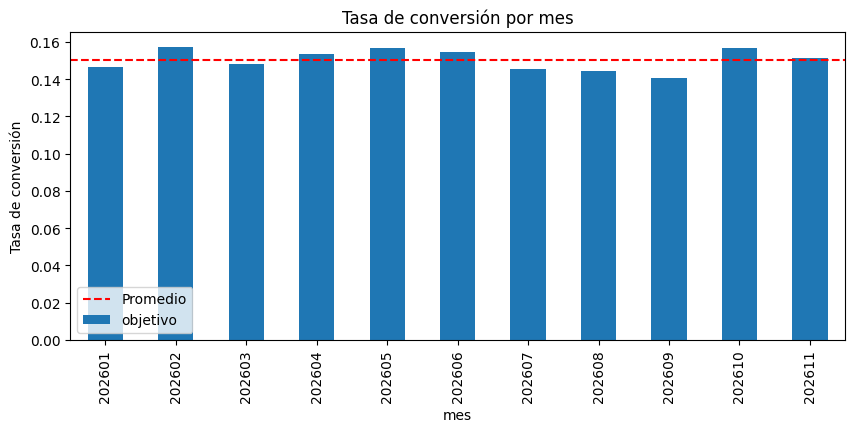

In [16]:
# Tasa de conversión por mes
tasa_mes = train.groupby("mes")["objetivo"].mean()
tasa_mes.plot(kind="bar", figsize=(10, 4), title="Tasa de conversión por mes")
plt.axhline(train["objetivo"].mean(), color="red", linestyle="--", label="Promedio")
plt.ylabel("Tasa de conversión"); plt.legend(); plt.show()

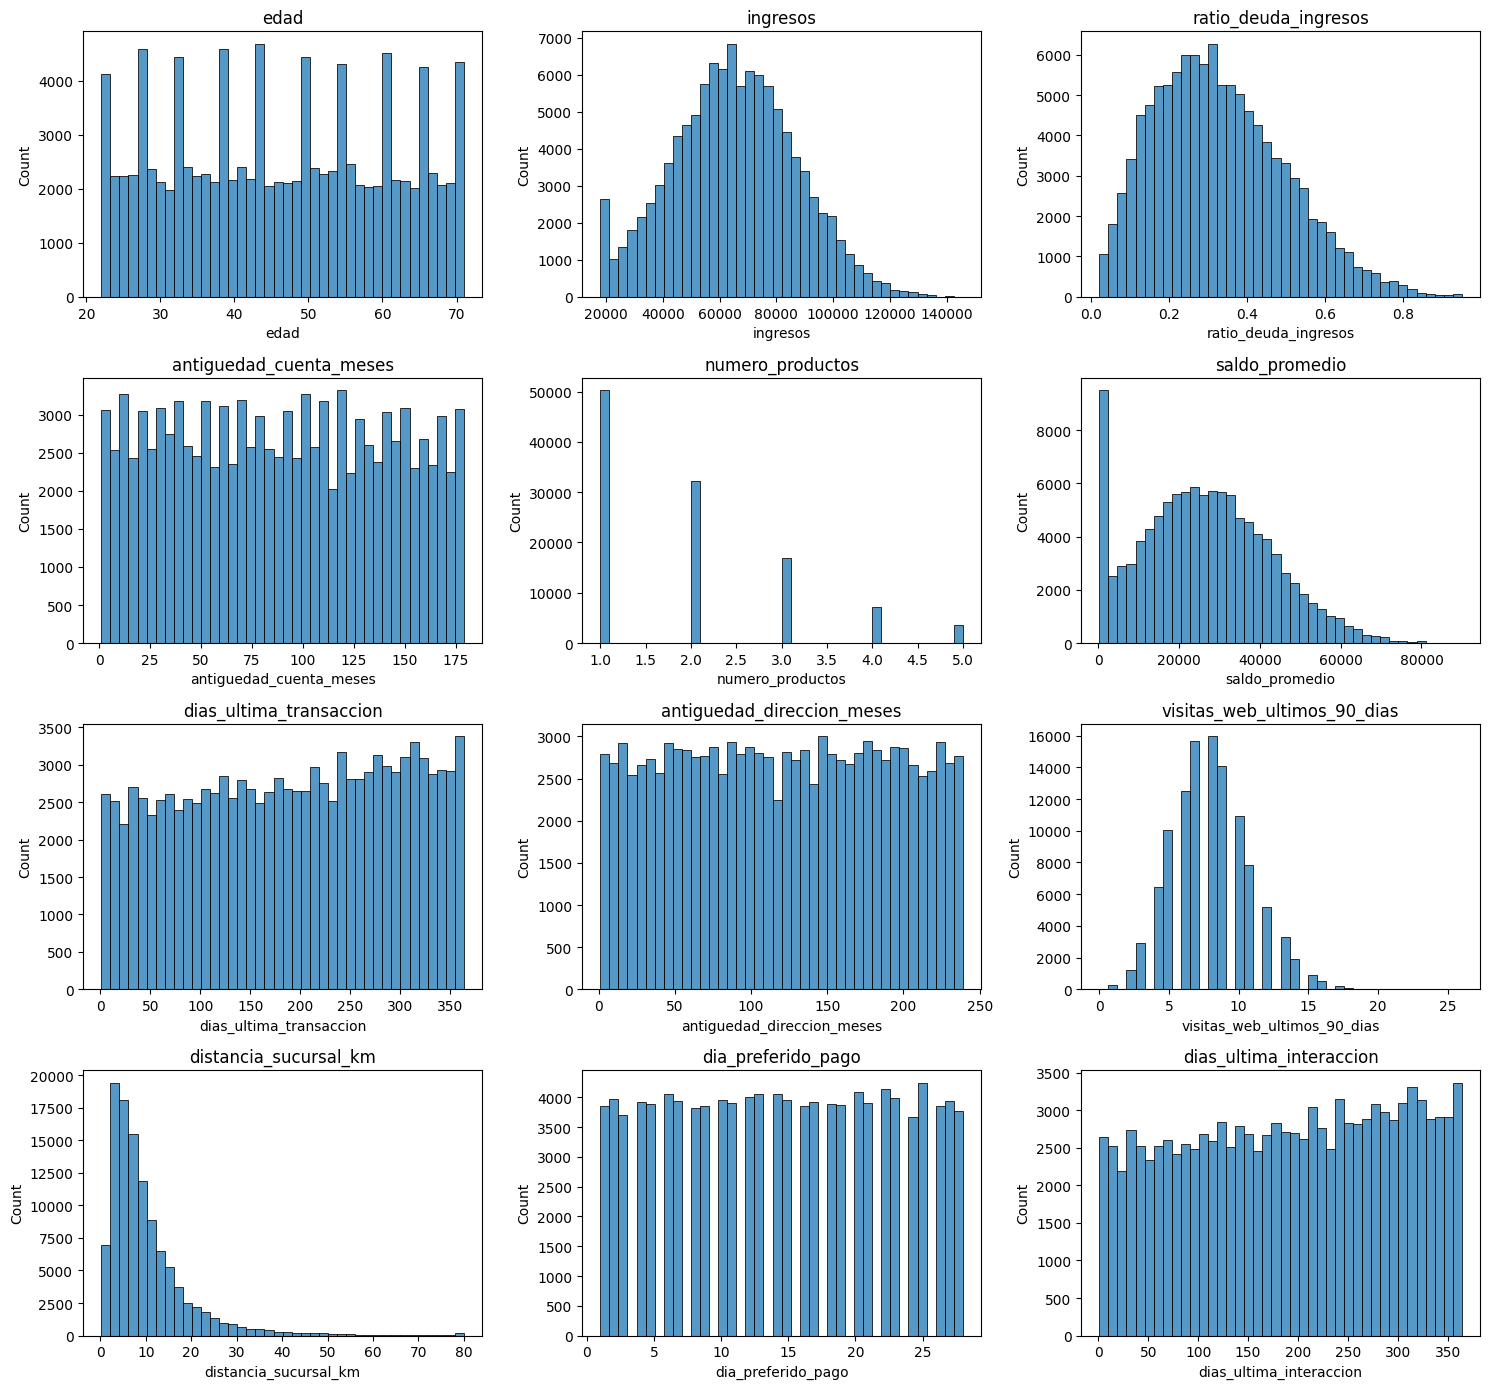

In [17]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, col in zip(axes.flat, numericas):
    sns.histplot(train[col], bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

# La tasa de conversión mensual se mantiene estable entre 14,1% y 15,7 (promedio 15,05%), sin tendencia ni estacionalidad. Esto indica que el comportamiento de diciembre debería ser similar al de los meses de entrenamiento y que la variable mes no aporta poder predictivo por sí misma.

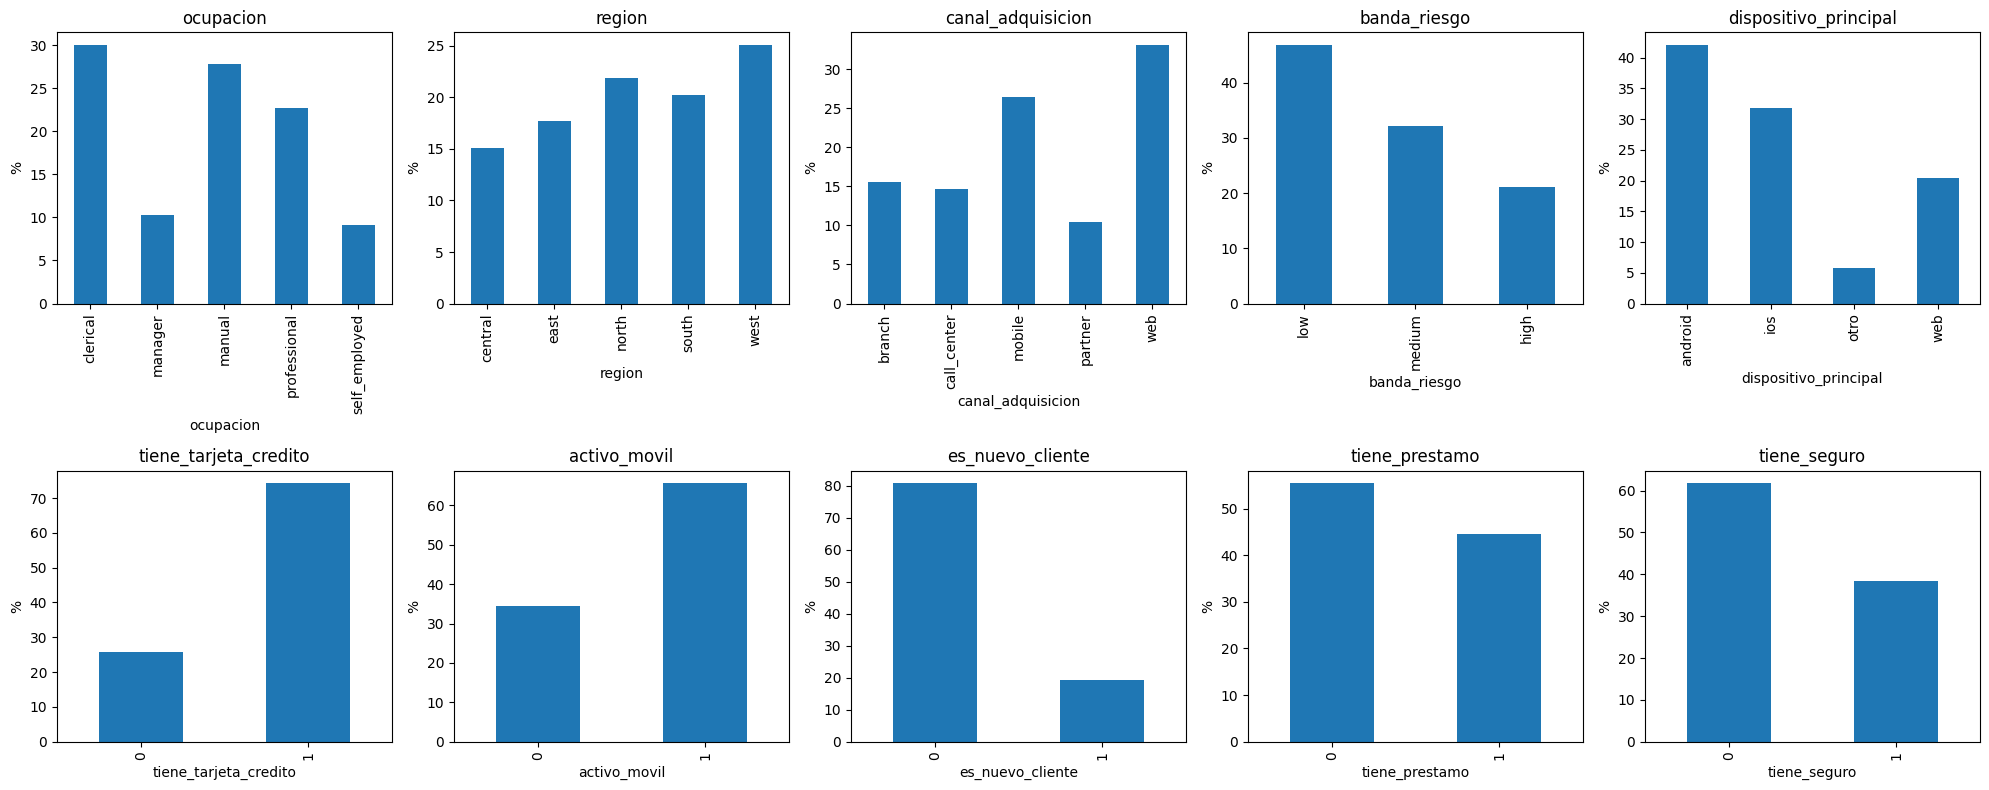

In [18]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.flat, categoricas + booleanas):
    (train[col].value_counts(normalize=True) * 100).sort_index().plot(kind="bar", ax=ax)
    ax.set_title(col); ax.set_ylabel("%")
plt.tight_layout(); plt.show()

,variable,Gini,direccion
0,banda_riesgo,0.1586,"↓ más valor, menos conversión"
1,numero_productos,0.1136,"↑ más valor, más conversión"
2,dias_ultima_transaccion,0.0929,"↓ más valor, menos conversión"
3,dias_ultima_interaccion,0.0579,"↓ más valor, menos conversión"
4,activo_movil,0.0396,"↑ más valor, más conversión"
5,tiene_tarjeta_credito,0.0224,"↑ más valor, más conversión"
6,canal_adquisicion,0.0195,"↑ más valor, más conversión"
7,antiguedad_cuenta_meses,0.0175,"↑ más valor, más conversión"
8,ratio_deuda_ingresos,0.0173,"↓ más valor, menos conversión"
9,ocupacion,0.0135,"↑ más valor, más conversión"


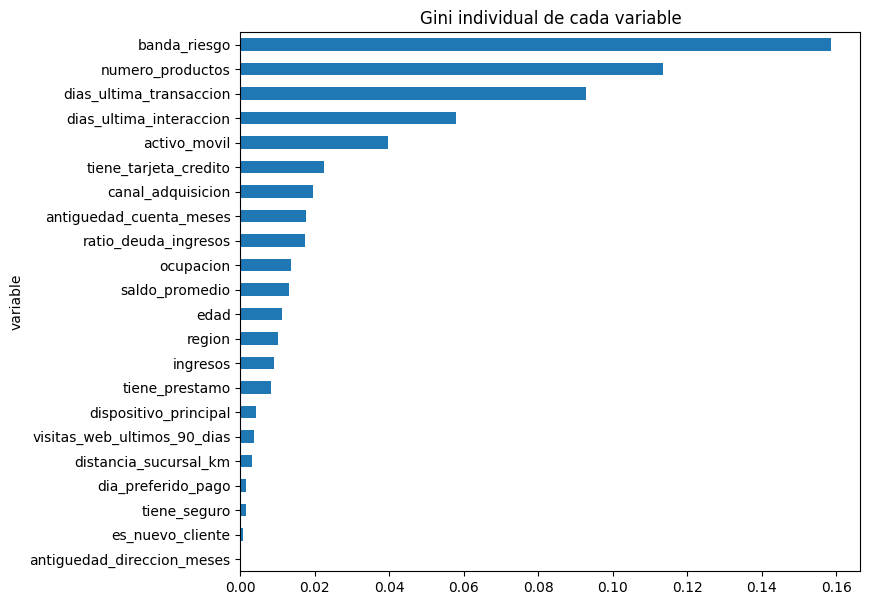

In [19]:
from sklearn.metrics import roc_auc_score

resultados = []
for col in numericas + booleanas + categoricas:
    if col in categoricas and col != "banda_riesgo":
        # Categóricas nominales: usamos la tasa de conversión de su categoría
        x = train.groupby(col, observed=True)["objetivo"].transform("mean")
    elif col == "banda_riesgo":
        x = train[col].cat.codes          # low=0, medium=1, high=2
    else:
        x = train[col]
    auc = roc_auc_score(train["objetivo"], x)
    resultados.append({"variable": col,
                       "Gini": abs(2 * auc - 1),
                       "direccion": "↑ más valor, más conversión" if auc > 0.5 else "↓ más valor, menos conversión"})

gini_ind = pd.DataFrame(resultados).sort_values("Gini", ascending=False).reset_index(drop=True)
display(gini_ind.round(4))

gini_ind.sort_values("Gini").plot.barh(x="variable", y="Gini", figsize=(8, 7), legend=False,
                                       title="Gini individual de cada variable")
plt.show()

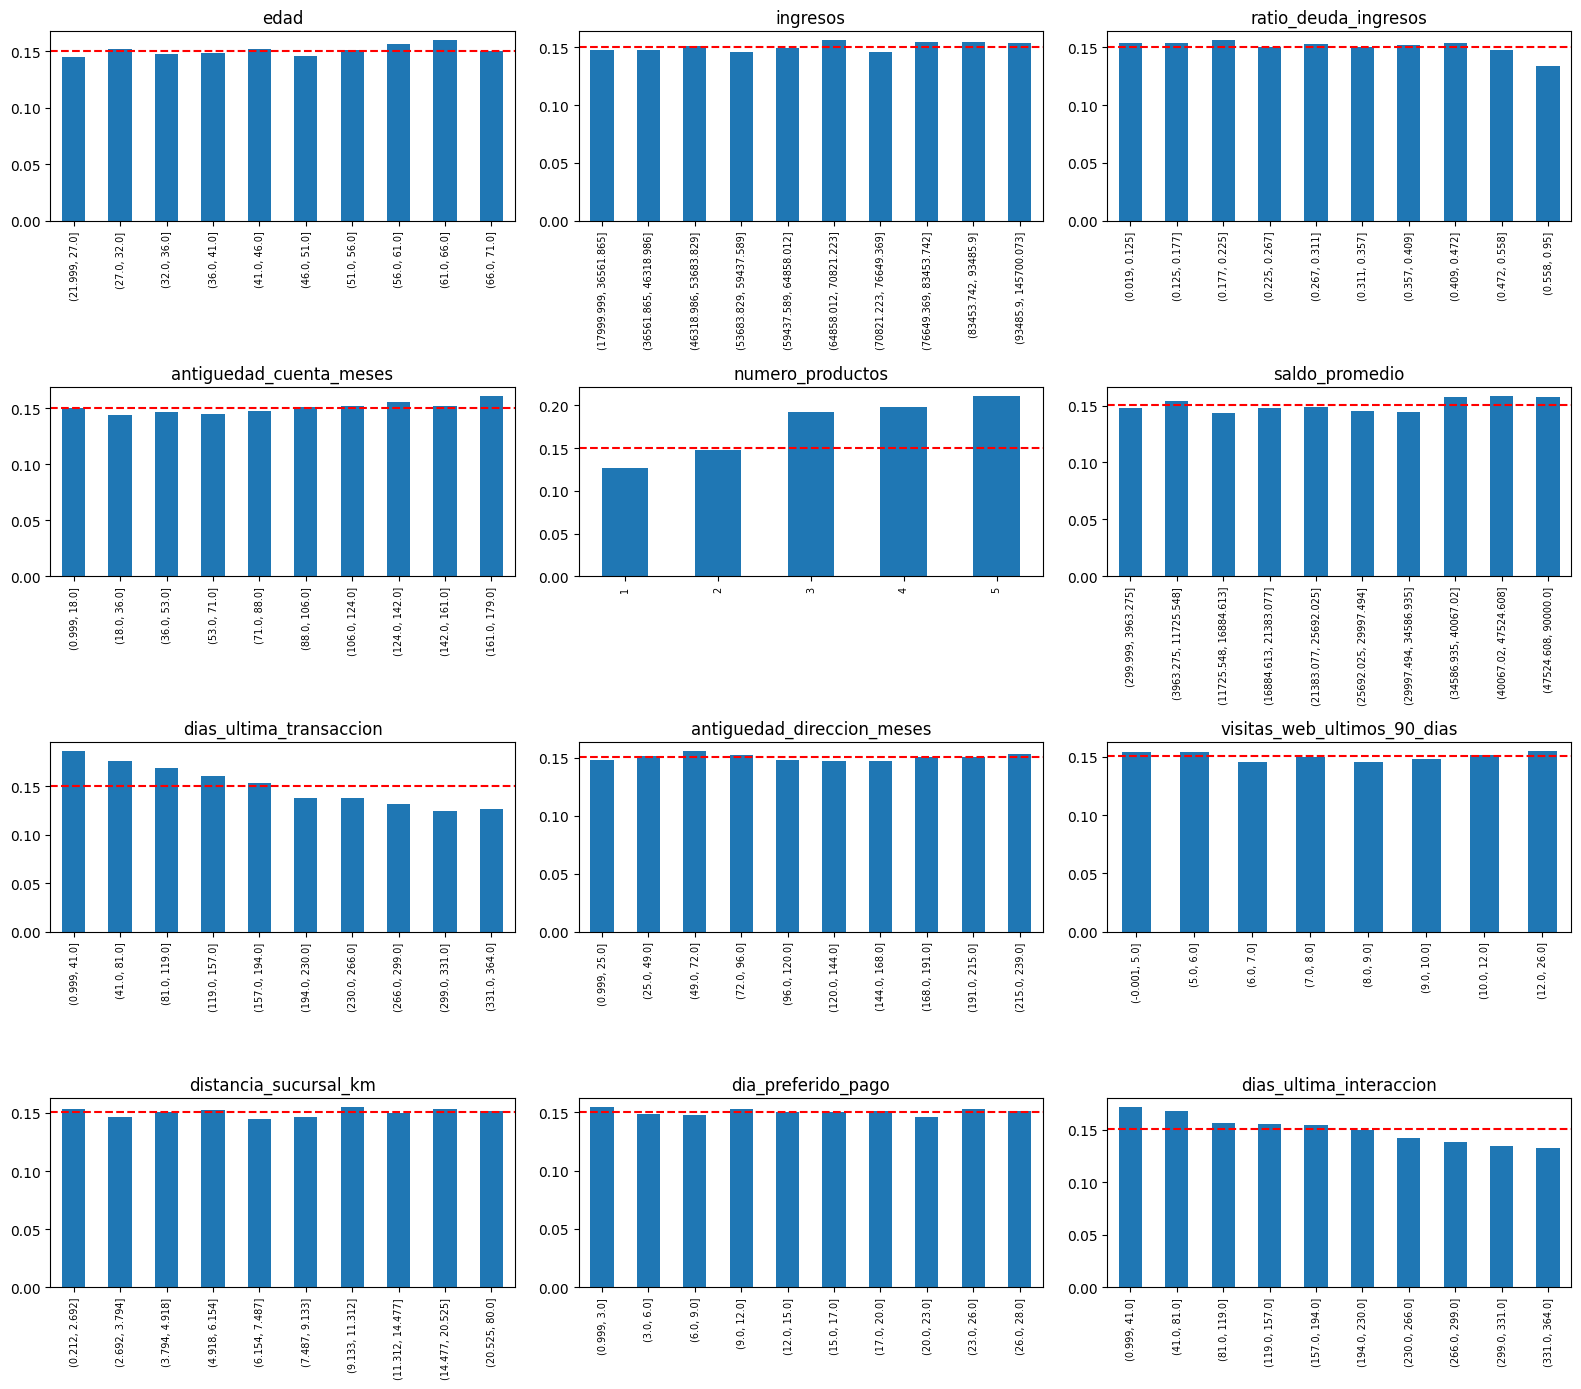

In [20]:
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.flat, numericas):
    if train[col].nunique() <= 10:
        grupos = train[col]                                     # pocos valores: uno por uno
    else:
        grupos = pd.qcut(train[col], q=10, duplicates="drop")   # muchos valores: 10 grupos iguales
    tasa = train.groupby(grupos, observed=True)["objetivo"].mean()
    tasa.plot(kind="bar", ax=ax)
    ax.axhline(train["objetivo"].mean(), color="red", linestyle="--")
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

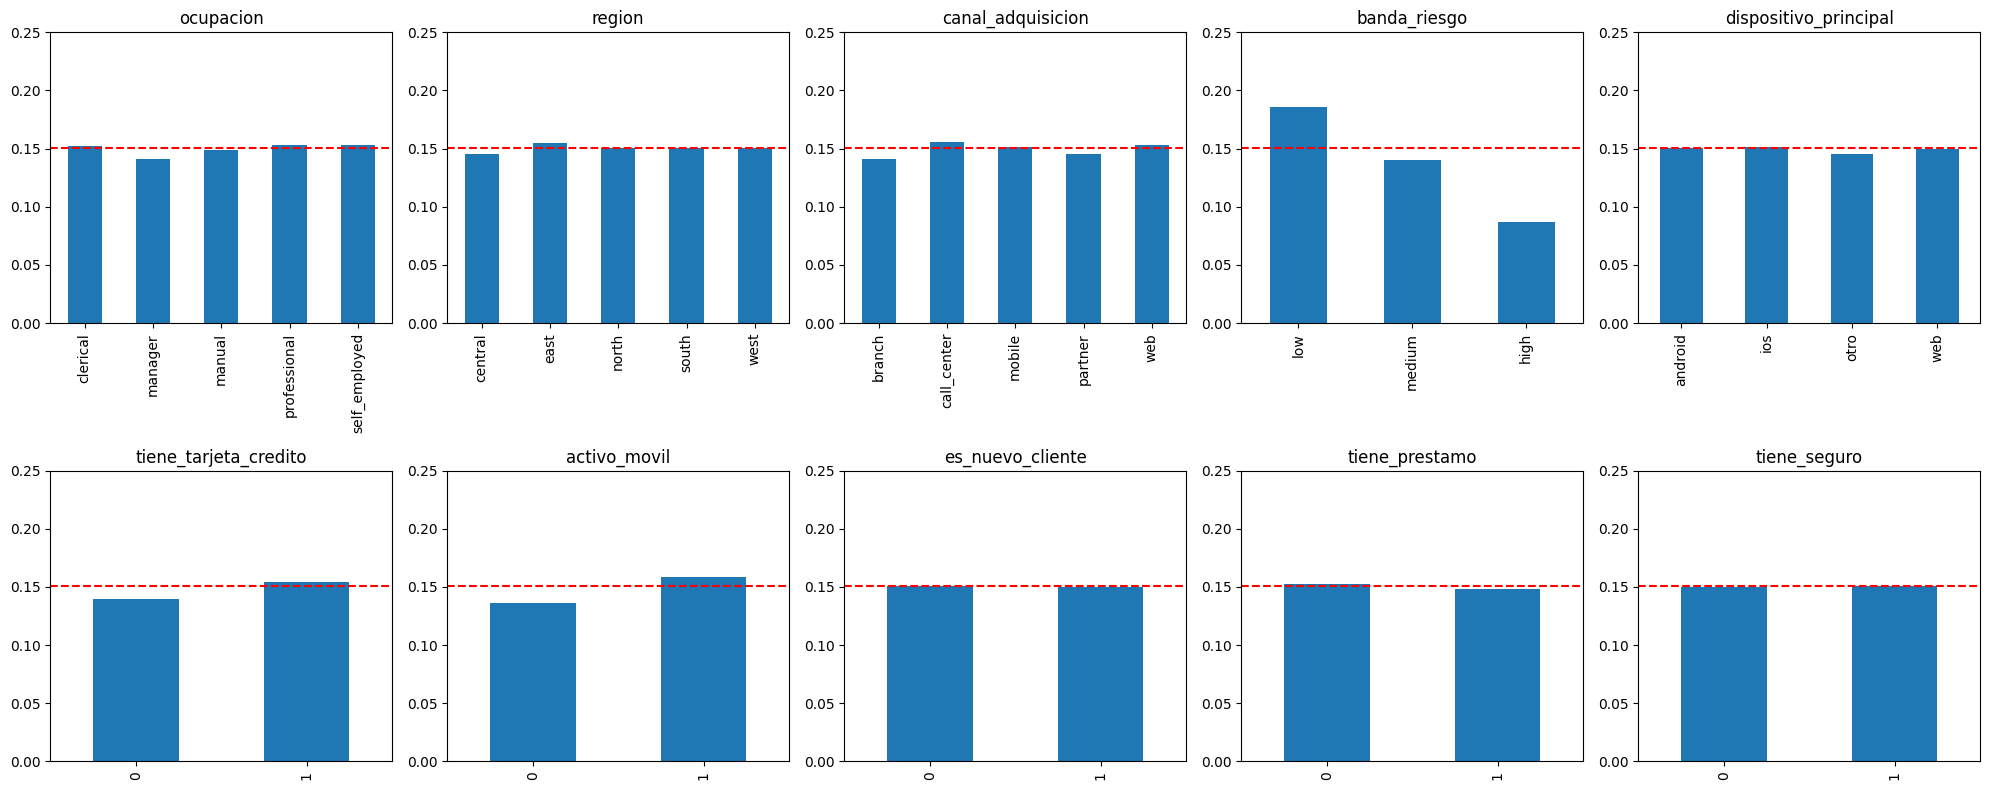

In [21]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.flat, categoricas + booleanas):
    train.groupby(col, observed=True)["objetivo"].mean().plot(kind="bar", ax=ax)
    ax.axhline(train["objetivo"].mean(), color="red", linestyle="--")
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylim(0, 0.25)
plt.tight_layout(); plt.show()

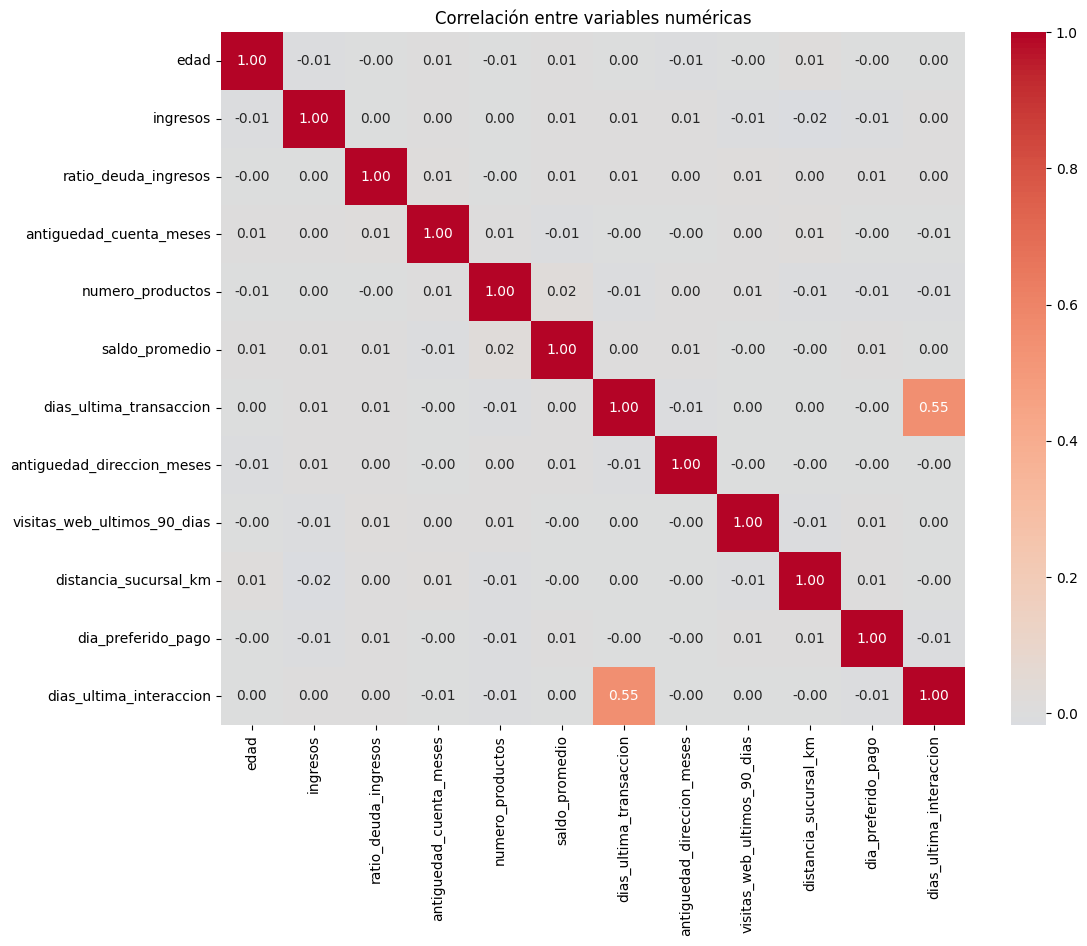

In [22]:
plt.figure(figsize=(12, 9))
sns.heatmap(train[numericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas"); plt.show()

In [24]:
# Combina las dos variables más fuertes: muchos productos + bajo riesgo = valor alto
# banda_riesgo: low=0, medium=1, high=2  ->  (3 - riesgo): low=3, medium=2, high=1
for df in [train, test]:
    df["productos_x_riesgo"] = df["numero_productos"] * (3 - df["banda_riesgo"].cat.codes)

FEATURES = numericas + categoricas + booleanas + ["productos_x_riesgo"]   # 23 variables
print(len(FEATURES), "variables")

23 variables


In [25]:
MESES_VALIDACION = [202609, 202610, 202611]

def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1           # fórmula de la competencia

def validar(crear_modelo, nombre):
    ginis = []
    for mes_val in MESES_VALIDACION:
        tr = train[train["mes"] < mes_val]       # entrena SOLO con meses anteriores
        va = train[train["mes"] == mes_val]      # predice el mes siguiente
        modelo = crear_modelo()
        modelo.fit(tr[FEATURES], tr["objetivo"])
        prob = modelo.predict_proba(va[FEATURES])[:, 1]
        ginis.append(gini(va["objetivo"], prob))
    print(f"{nombre:22s} sep={ginis[0]:.4f}  oct={ginis[1]:.4f}  nov={ginis[2]:.4f}  -> PROMEDIO={np.mean(ginis):.4f}")

In [27]:
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

def crear_logistica():
    prep = ColumnTransformer([
        ("num", StandardScaler(), numericas + booleanas + ["productos_x_riesgo"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)])
    return make_pipeline(prep, LogisticRegression(max_iter=2000))

validar(crear_logistica, "Regresión logística")

Regresión logística    sep=0.2374  oct=0.2456  nov=0.2155  -> PROMEDIO=0.2328


In [29]:
# Parámetros encontrados con Optuna (60 pruebas)
PARAMS = dict(
    n_estimators=700,          # 700 árboles
    learning_rate=0.009896,    # aprende despacio
    max_depth=5, num_leaves=7, # árboles pequeños
    min_child_samples=276,     # cada decisión basada en 276+ clientes
    subsample=0.7527, subsample_freq=1,   # cada árbol ve el 75% de filas
    colsample_bytree=0.9670,   # cada árbol ve el 97% de variables
    reg_lambda=2.3152, reg_alpha=0.005714, min_split_gain=0.04646,
    verbose=-1)

def crear_lgbm():
    return lgb.LGBMClassifier(**PARAMS, random_state=42)

validar(crear_lgbm, "LightGBM final")

LightGBM final         sep=0.2496  oct=0.2702  nov=0.2441  -> PROMEDIO=0.2546


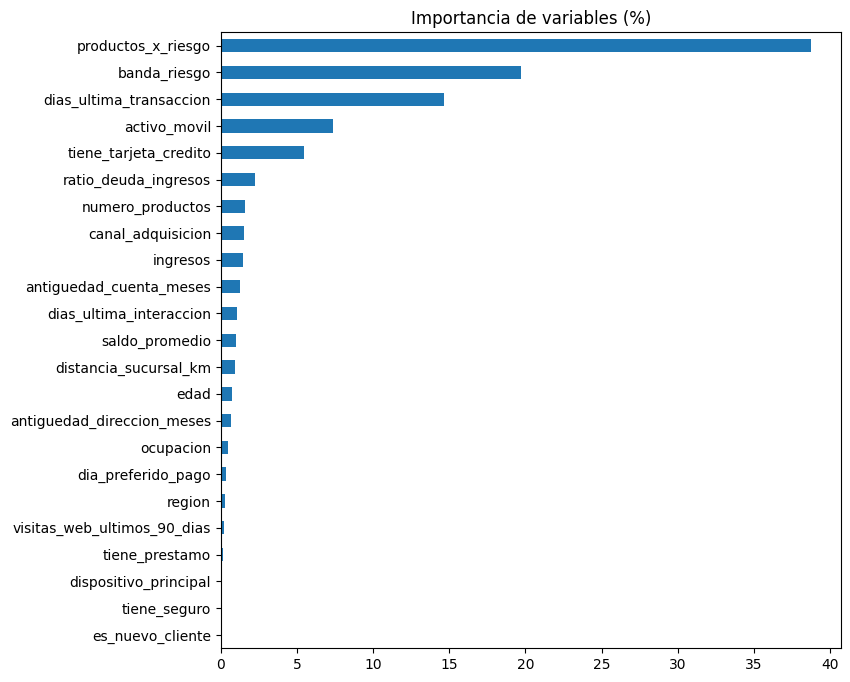

In [30]:
modelo = crear_lgbm().fit(train[FEATURES], train["objetivo"])
imp = pd.Series(modelo.booster_.feature_importance("gain"), index=FEATURES)
(imp / imp.sum() * 100).sort_values().plot.barh(figsize=(8, 8), title="Importancia de variables (%)")
plt.show()

In [31]:
pred = np.zeros(len(test))
for semilla in [1, 2, 3, 4, 5]:                       # 5 modelos y se promedian
    m = lgb.LGBMClassifier(**PARAMS, random_state=semilla)
    m.fit(train[FEATURES], train["objetivo"])         # TODOS los meses
    pred += m.predict_proba(test[FEATURES])[:, 1] / 5

submission = pd.DataFrame({"id_cliente": test["id_cliente"], "prediccion": pred})

# Verificaciones
assert len(submission) == 9900
assert submission["id_cliente"].equals(test["id_cliente"])
assert submission["prediccion"].between(0, 1).all()

submission.to_csv(f"{RUTA}/submission_final.csv", index=False)
print("Guardado en Drive:", f"{RUTA}/submission_final.csv")
submission.head()

Guardado en Drive: /content/drive/MyDrive/bcp/submission_final.csv


,id_cliente,prediccion
0,2,0.144678
1,3,0.065937
2,7,0.132055
3,10,0.062504
4,11,0.143288


In [32]:
validar(crear_lgbm, "LightGBM final")

LightGBM final         sep=0.2496  oct=0.2702  nov=0.2441  -> PROMEDIO=0.2546
